# Estimadores de cohorte, de duración y de Aalen-Johansen sobre CEREP

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 01 de este tema (cohortes, la PD a un año y el promedio de largo plazo)
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este cuaderno puedes:

- agrupar las tablas de cohortes anuales en una matriz con el estimador de Anderson y Goodman y poner tres intervalos (Wald, Agresti-Coull, Jeffreys) a la PD de un grado delgado;
- decir qué no ve el estimador de cohorte (lo que ocurre dentro del año) y qué usa en su lugar el estimador de duración (cada salto y el tiempo pasado en cada grado);
- calcular un generador de duración, una matriz de Aalen-Johansen y un generador EM sobre un conjunto de trayectorias de calificación cuyo generador verdadero se conoce, y leer cada uno contra la verdad;
- explicar, con cada intermedio impreso, por qué el estimador de duración da una PD distinta de cero a un grado donde el estimador de cohorte no vio ningún incumplimiento;
- leer la evidencia versionada de 200 simulaciones sobre cuántas veces cada estimador devuelve exactamente cero y qué tan grande es su error.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.transitions import embedding, estimators, intervals
from riskvalidation.transitions.em import em_generator
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Mostrar un valor lógico o una etiqueta del motor en español, también dentro de listas y diccionarios
ETIQUETAS = {
    "green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada", "illustrative": "ilustrativa",
    "synthetic-calibrated": "sintética calibrada", "withheld-derived-only": "retenidas, solo derivados", "included": "incluidas",
    "fitted": "ajustado", "challenger-not-run": "retador no ejecutado",
}


def si_no(valor):
    if isinstance(valor, dict):
        return {ETIQUETAS.get(k, k): si_no(v) for k, v in valor.items()}
    if getattr(valor, 'ndim', 0) > 0:
        return si_no(valor.tolist())
    if isinstance(valor, (list, tuple)):
        return [si_no(v) for v in valor]
    if isinstance(valor, str):
        return ETIQUETAS.get(valor, valor)
    return "sí" if valor else "no"

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cuatro archivos versionados del caso C04, todos derivados de la publicación CEREP de ESMA (clase de licencia `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/):

- `data/derived/C04/sp.json`: las cohortes anuales de S&P (26 tablas, 2000 a 2025), la matriz agrupada y los generadores.
- `data/derived/C04/fitch.json`: lo mismo para Fitch (24 cohortes anuales), para comparar entre agencias.
- `data/derived/C04/models-transitions.json`: el generador que el caso ajustó a los conteos de S&P por EM (`fit.generator.q`) y el número de deudores desde el que simula (`fit.generator.obligors`). Este generador es la **verdad conocida** de la segunda mitad del cuaderno.
- `data/derived/C04/markov.json`: el estudio de simulación versionado, 200 conjuntos de datos con semilla sacados de ese generador, con el sesgo y el error de seis estimadores.

CEREP publica instantáneas (las calificaciones al 1 de enero y al 31 de diciembre), nunca trayectorias individuales, así que los estimadores de tiempo continuo no se pueden correr sobre las tablas reales: necesitan la fecha de cada salto. Por eso el cuaderno saca **un** conjunto de trayectorias desde el generador versionado con el `RatingPaths` del motor: es pequeño (una fracción de segundo), tiene semilla, y cada estimador se puede comparar con el generador que lo hizo.

La celda siguiente carga los archivos e imprime lo que contienen.

In [2]:
# Cargar los cuatro artefactos (el cuaderno está tres carpetas bajo la raíz del repositorio) e imprimir lo que contienen
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
sp = json.loads((C04 / "sp.json").read_text(encoding="utf-8"))
fitch = json.loads((C04 / "fitch.json").read_text(encoding="utf-8"))
models = json.loads((C04 / "models-transitions.json").read_text(encoding="utf-8"))
markov = json.loads((C04 / "markov.json").read_text(encoding="utf-8"))
out = sp["outputs"]
grades, states = out["grades"], out["states"]

for label, doc in (("sp", sp), ("fitch", fitch), ("models-transitions", models), ("markov", markov)):
    print(f"{label:20s} calculado con riskvalidation", doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("cohortes anuales de S&P:", len(out["cohorts"]), "| Fitch:", len(fitch["outputs"]["cohorts"]))
print("deudores que simula el generador verdadero, por grado:", models["fit"]["generator"]["obligors"])
print("estudio de simulación: simulaciones:", markov["outputs"]["design"]["reps"], "| años:", markov["outputs"]["design"]["years"])

sp                   calculado con riskvalidation 1.0.1 | instalado 1.0.1
fitch                calculado con riskvalidation 1.0.1 | instalado 1.0.1
models-transitions   calculado con riskvalidation 1.0.1 | instalado 1.0.1
markov               calculado con riskvalidation 1.0.1 | instalado 1.0.1
cohortes anuales de S&P: 26 | Fitch: 24
deudores que simula el generador verdadero, por grado: [75, 822, 1814, 1756, 1054, 1391, 201]
estudio de simulación: simulaciones: 200 | años: 5


## Método

### Paso 1: agrupar las cohortes anuales

Una cohorte da a cada grado unos cientos de calificaciones, y una transición rara puede no aparecer en ella. Anderson y Goodman (1957, ecuación 2.8) agrupan los períodos bajo homogeneidad en el tiempo: suman las entradas correspondientes de las tablas de conteos y dividen cada fila por su total,

$$\hat p_{ij} = \frac{\sum_t N_{ij}(t)}{\sum_t \sum_k N_{ik}(t)}$$

Primero se quitan las calificaciones retiradas de cada año (el tratamiento de la industria del cuaderno 01). Los años con más calificaciones pesan más, por lo que la tasa agrupada no es el promedio de las tasas anuales del cuaderno 01. La celda siguiente llama al `pooled_cohort` del motor sobre las 26 tablas y verifica el resultado: las filas suman uno, ninguna entrada es negativa y es igual a la matriz agrupada que versiona el artefacto.

In [3]:
# Agrupar las 26 tablas anuales con el motor y verificar la matriz contra la versionada
tables = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in out["cohorts"]]
withdrawn = [np.append(np.array(c["withdrawn"], dtype=float), 0.0) for c in out["cohorts"]]
pooled = estimators.pooled_cohort(tables, withdrawn, treatment="exclude")
p_pooled = pooled["matrix"]

print("períodos agrupados:", pooled["periods"], "| filas sin calificaciones:", pooled["empty_rows"])
print("las filas suman uno:", si_no(np.allclose(p_pooled.sum(axis=1), 1.0)), "| ninguna entrada negativa:", si_no(np.all(p_pooled >= 0)))
print("mayor diferencia con la matriz versionada:", float(np.abs(p_pooled - np.array(out["pooled"]["matrix"])).max()))
print(f"{'grado':8s}{'calificaciones agrupadas':>30s}{'incumplimientos':>16s}{'PD agrupada':>14s}")
for g in range(7):
    print(f"{grades[g]:8s}{pooled['row_sizes'][g]:30.0f}{pooled['counts'][g, -1]:16.0f}{p_pooled[g, -1]:14.6f}")

períodos agrupados: 26 | filas sin calificaciones: []
las filas suman uno: sí | ninguna entrada negativa: sí
mayor diferencia con la matriz versionada: 0.0
grado         calificaciones agrupadas incumplimientos   PD agrupada
AAA                               1895               0      0.000000
AA                               20192               1      0.000050
A                                45073              13      0.000288
BBB                              42854              35      0.000817
BB                               24842              86      0.003462
B                                31712             372      0.011731
CCC-C                             3731             301      0.080675


### Paso 2: un intervalo para un grado delgado

La PD agrupada de AA descansa en un incumplimiento en unas veinte mil calificaciones, y la de AAA en ninguno. Una estimación puntual no dice nada de eso. El motor ofrece tres intervalos al 95%, todos en `transitions.intervals`: el intervalo de Wald $\hat p \pm z\sqrt{\hat p(1-\hat p)/n}$, el de Agresti-Coull, que agrega $z^2$ pseudo-observaciones antes de aplicar la fórmula de Wald, y el intervalo de Jeffreys de colas iguales, los cuantiles de $\mathrm{Beta}(D + \tfrac12,\, n - D + \tfrac12)$ (Brown, Cai y DasGupta, 2001). Schuermann y Hanson (2004) usan los dos primeros para las PD por grado. La celda siguiente llama a los tres sobre los conteos agrupados y los verifica contra los intervalos que el artefacto versiona para la misma definición.

In [4]:
# Llamar a los tres métodos de intervalo sobre los incumplimientos y calificaciones agrupados, y comparar con los intervalos versionados
defaults = pooled["counts"][:7, -1]
ratings = pooled["row_sizes"][:7]
committed = out["lra"]["d4"]
print(f"{'grado':8s}{'Wald':>26s}{'Agresti-Coull':>26s}{'Jeffreys':>26s}")
agree = True
for name, fn in (("wald", intervals.pd_wald), ("agresti_coull", intervals.pd_agresti_coull), ("jeffreys", intervals.pd_jeffreys)):
    result = fn(defaults, ratings, level=0.95)
    agree &= bool(np.allclose(result["lower"], committed[name]["lower"], atol=1e-8) and np.allclose(result["upper"], committed[name]["upper"], atol=1e-8))
    if name == "wald":
        wald, ac, jef = result, None, None
    elif name == "agresti_coull":
        ac = result
    else:
        jef = result
for g in range(7):
    row = "".join(f"{r['lower'][g]:12.5f} to {r['upper'][g]:.5f}"[:26].rjust(26) for r in (wald, ac, jef))
    print(f"{grades[g]:8s}{row}")
print("igual a los intervalos versionados:", si_no(agree))
print("AAA: incumplimientos observados:", int(defaults[0]), "| largo de Wald:", wald["length"][0], "| cota superior de Jeffreys:", round(float(jef["upper"][0]), 5))

grado                         Wald             Agresti-Coull                  Jeffreys
AAA             0.00000 to 0.00000        0.00000 to 0.00244        0.00000 to 0.00132
AA              0.00000 to 0.00015        0.00000 to 0.00031        0.00001 to 0.00023
A               0.00013 to 0.00045        0.00016 to 0.00050        0.00016 to 0.00048
BBB             0.00055 to 0.00109        0.00058 to 0.00114        0.00058 to 0.00112
BB              0.00273 to 0.00419        0.00280 to 0.00428        0.00279 to 0.00425
B               0.01055 to 0.01292        0.01060 to 0.01298        0.01059 to 0.01296
CCC-C           0.07194 to 0.08941        0.07235 to 0.08986        0.07226 to 0.08974
igual a los intervalos versionados: sí
AAA: incumplimientos observados: 0 | largo de Wald: 0.0 | cota superior de Jeffreys: 0.00132


Un grado sin incumplimientos observados recibe un intervalo de Wald de ancho cero: el estimador está seguro de una PD que no descansa en nada. Los otros dos conservan una cota superior. El cuaderno 10 mide con qué frecuencia cada intervalo contiene la verdad cuando un grado es delgado.

### Paso 3: un conjunto de datos cuya verdad se conoce

El generador que el caso ajustó a los conteos de S&P es aquí la verdad. La celda siguiente lo lee de `models-transitions.json`, verifica que es un generador válido (entradas fuera de la diagonal no negativas, filas que suman cero, incumplimiento absorbente) y calcula su PD a un año por grado, la columna de incumplimiento de $\exp(Q)$. Luego `RatingPaths` saca, con un flujo aleatorio con semilla, la trayectoria de calificación de cada deudor durante cinco años, observada en instantáneas anuales como CEREP. La simulación es exacta: el motor simula la cadena en tiempo continuo, así que las trayectorias guardan la fecha de cada salto, algo que una tabla real de CEREP no tiene.

In [5]:
# Leer el generador verdadero, verificarlo y sacar un conjunto de trayectorias con semilla observadas en instantáneas anuales
q_true = np.array(models["fit"]["generator"]["q"], dtype=float)
n_obligors = tuple(models["fit"]["generator"]["obligors"])
pd_true = expm(q_true)[:7, -1]

print("generador válido:", si_no(embedding.is_generator(q_true)))
print("tiempo medio en cada grado antes de salir (años):", np.round(-1.0 / np.diag(q_true)[:7], 2))

generator = RatingPaths(q_true, n_obligors, horizon=5.0, snapshots=tuple(float(t) for t in range(6)))
data = generator.draw(np.random.default_rng(20261021))
segments, steps = data["segments"], data["steps"]
print("deudores:", int(sum(n_obligors)), "| segmentos (uno por estadía en un grado):", len(segments["obligor"]), "| tablas de instantáneas anuales:", len(steps))
print(f"{'grado':8s}{'PD a un año verdadera':>26s}")
for g in range(7):
    print(f"{grades[g]:8s}{pd_true[g]:26.6f}")

generador válido: sí
tiempo medio en cada grado antes de salir (años): [ 5.12  8.51 15.69 13.36  7.22  6.59  2.89]
deudores: 7113 | segmentos (uno por estadía en un grado): 10953 | tablas de instantáneas anuales: 5
grado        PD a un año verdadera
AAA                       0.000066
AA                        0.000049
A                         0.000288
BBB                       0.000817
BB                        0.003462
B                         0.011731
CCC-C                     0.080618


### Paso 4: el estimador de cohorte frente al estimador de duración

Sobre los mismos deudores, dos lecturas. El estimador de cohorte ve solo las cinco instantáneas anuales: las agrupa con la ecuación 2.8 y lee la columna de incumplimiento. El estimador de duración (Lando y Skodeberg, 2002) usa cada salto y el tiempo que cada deudor pasó en cada grado. Para una cadena homogénea en el tiempo observada de forma continua, la verosimilitud se maximiza con

$$\hat q_{ij} = \frac{K_{ij}}{S_i}, \quad i \neq j, \qquad \hat q_{ii} = -\sum_{j \neq i} \hat q_{ij}$$

con $K_{ij}$ el número de saltos observados de $i$ a $j$ y $S_i$ el tiempo total pasado en $i$; la matriz a un año es $P = \exp(\hat Q)$. Una calificación puede ir de AAA a AA, a A, ... hasta el incumplimiento dentro de un año, y el estimador de duración ve cada paso, mientras que una instantánea ve solo el comienzo y el final. La celda siguiente imprime los saltos y los tiempos de permanencia, verifica el generador y pone las dos PD junto a la verdad.

In [6]:
# El generador de duración desde las trayectorias (K_ij / S_i) y el estimador de cohorte agrupado desde las instantáneas anuales, junto a la verdad
dur = estimators.duration_generator(segments, len(states))
q_dur = dur["generator"]
jumps, holding = np.array(dur["jumps"]), np.array(dur["holding"])
print("saltos K desde el grado AAA (a AAA..D):", jumps[0].astype(int))
print("tiempo S pasado en cada grado (deudor-años):", np.round(holding[:7], 1))
print("la primera fila de Q es K / S:", si_no(np.allclose(q_dur[0, 1:], jumps[0, 1:] / holding[0])))
print("generador válido:", si_no(embedding.is_generator(q_dur)), "| estados nunca abandonados:", dur["unobserved"])

cohort_5 = estimators.pooled_cohort([s["counts"] for s in steps])
pd_cohort = cohort_5["matrix"][:7, -1]
pd_dur = expm(q_dur)[:7, -1]
print(f"{'grado':8s}{'verdad':>12s}{'cohorte':>12s}{'duración':>12s}{'incumplimientos vistos en instantáneas':>46s}")
for g in range(7):
    print(f"{grades[g]:8s}{pd_true[g]:12.6f}{pd_cohort[g]:12.6f}{pd_dur[g]:12.6f}{cohort_5['counts'][g, -1]:46.0f}")

saltos K desde el grado AAA (a AAA..D): [ 0 54  0  0  0  1  1  0]
tiempo S pasado en cada grado (deudor-años): [ 240.2 3674.1 9263.6 8977.5 5090.  6432.9 1313.1]
la primera fila de Q es K / S: sí
generador válido: sí | estados nunca abandonados: []
grado         verdad     cohorte    duración        incumplimientos vistos en instantáneas
AAA         0.000066    0.000000    0.000204                                             0
AA          0.000049    0.000000    0.000013                                             0
A           0.000288    0.000217    0.000257                                             2
BBB         0.000817    0.000895    0.000932                                             8
BB          0.003462    0.004480    0.004808                                            23
B           0.011731    0.013231    0.012517                                            86
CCC-C       0.080618    0.087678    0.089439                                           111


Ninguno de los dos estimadores vio un incumplimiento de AAA: el conteo de saltos `K` de la fila AAA hacia el incumplimiento es cero. El estimador de cohorte lee entonces exactamente cero. El estimador de duración sí vio deudores AAA saltar a B y a CCC-C dentro del año, y la exponencial de matriz encadena esos saltos con las tasas de incumplimiento de B y de CCC-C, por lo que devuelve una PD positiva. Un conjunto de datos es una muestra, así que el número de duración puede quedar sobre o bajo la verdad (aquí sobre ella para AAA, bajo ella para AA); el paso 7 lee lo que dicen 200 simulaciones sobre el tamaño del error.

### Paso 5: Aalen-Johansen, sin homogeneidad en el tiempo

El estimador de duración supone un solo generador para todo el período. Aalen y Johansen (1978) lo abandonan: estiman la matriz de transición entre dos fechas $s < t$ como el producto, sobre los instantes de salto observados $u$ en $(s, t]$, de la identidad más el incremento de Nelson-Aalen,

$$\hat P(s, t) = \prod_{s < u \le t} \bigl(I + d\hat A(u)\bigr), \qquad d\hat A_{ij}(u) = \frac{dN_{ij}(u)}{Y_i(u-)}$$

con $dN_{ij}(u)$ los saltos de $i$ a $j$ en $u$ y $Y_i(u-)$ los deudores en $i$ justo antes de $u$. No necesita generador ni homogeneidad, y siendo un producto en el tiempo cumple exactamente la identidad de Chapman-Kolmogorov $\hat P(0, 2) = \hat P(0, 1)\,\hat P(1, 2)$. La celda siguiente calcula las matrices del primer año, del segundo y de los dos primeros años, y verifica esa identidad.

In [7]:
# Matrices de Aalen-Johansen sobre las mismas trayectorias, la identidad de Chapman-Kolmogorov y la PD junto a la verdad
aj01 = estimators.aalen_johansen(segments, len(states), 0.0, 1.0)["matrix"]
aj12 = estimators.aalen_johansen(segments, len(states), 1.0, 2.0)["matrix"]
aj02 = estimators.aalen_johansen(segments, len(states), 0.0, 2.0)["matrix"]

print("las filas suman uno:", si_no(np.allclose(aj01.sum(axis=1), 1.0)))
print("P(0,2) iguala P(0,1) por P(1,2):", si_no(np.allclose(aj02, aj01 @ aj12)))
print(f"{'grado':8s}{'verdad':>12s}{'AJ P(0,1)':>12s}{'AJ P(1,2)':>12s}{'duración':>12s}")
for g in range(7):
    print(f"{grades[g]:8s}{pd_true[g]:12.6f}{aj01[g, -1]:12.6f}{aj12[g, -1]:12.6f}{pd_dur[g]:12.6f}")

las filas suman uno: sí
P(0,2) iguala P(0,1) por P(1,2): sí
grado         verdad   AJ P(0,1)   AJ P(1,2)    duración
AAA         0.000066    0.000956    0.000001    0.000204
AA          0.000049    0.000005    0.000027    0.000013
A           0.000288    0.000081    0.000604    0.000257
BBB         0.000817    0.000178    0.001324    0.000932
BB          0.003462    0.005330    0.006910    0.004808
B           0.011731    0.015360    0.013384    0.012517
CCC-C       0.080618    0.077028    0.100631    0.089439


Los dos años difieren porque son dos muestras de la misma cadena (el generador es homogéneo en el tiempo aquí), que es el ruido que el estudio versionado promedia. Con una cadena que cambia en el tiempo las dos columnas diferirían por una razón, y solo Aalen-Johansen la seguiría.

### Paso 6: el generador EM, solo desde instantáneas

Un usuario de CEREP no tiene fechas de salto, solo las tablas anuales. Bladt y Sorensen (2005), como lo presentan Smith y dos Reis (2018), dan un generador por esperanza-maximización: encuentra el generador cuya exponencial de matriz hace más verosímiles los conteos de instantáneas observados, y el resultado es un generador válido por construcción. El `em_generator` del motor recibe la secuencia de tablas de conteos con el largo de cada paso. La celda siguiente lo corre dos veces: sobre las cinco tablas de instantáneas del conjunto simulado, y sobre las 26 cohortes reales de S&P, donde el resultado es el generador que versiona el artefacto.

In [8]:
# Generador EM sobre las instantáneas simuladas, y sobre las cohortes reales de S&P contra el generador versionado
em_sim = em_generator([{"counts": s["counts"], "dt": 1.0} for s in steps])
pd_em = expm(em_sim["generator"])[:7, -1]
print("instantáneas simuladas: iteraciones:", em_sim["iterations"], "| convergió:", si_no(em_sim["converged"]), "| generador válido:", si_no(embedding.is_generator(em_sim["generator"])))
print(f"{'grado':8s}{'verdad':>12s}{'EM':>12s}")
for g in range(7):
    print(f"{grades[g]:8s}{pd_true[g]:12.6f}{pd_em[g]:12.6f}")

em_real = em_generator([{"counts": t, "dt": 1.0} for t in tables])
committed_em = out["generators"]["em"]
print("cohortes reales de S&P: iteraciones:", em_real["iterations"], "(versionadas", committed_em["iterations"], ") | convergió:", si_no(em_real["converged"]))
gap = float(np.abs(em_real["generator"] - np.array(committed_em["generator"])).max())
print("mayor diferencia con el generador versionado bajo 1e-12:", si_no(gap < 1e-12), "(un residuo de redondeo: sus últimos dígitos siguen el número de hilos de BLAS)")
print("PD a un año, B y CCC-C, del generador EM:", np.round(expm(em_real["generator"])[5:7, -1], 5), "| versionada:", np.round(committed_em["pd_1y"][5:7], 5))

instantáneas simuladas: iteraciones: 42 | convergió: sí | generador válido: sí
grado         verdad          EM
AAA         0.000066    0.000025
AA          0.000049    0.000021
A           0.000288    0.000212
BBB         0.000817    0.000894
BB          0.003462    0.004480
B           0.011731    0.013231
CCC-C       0.080618    0.087625
cohortes reales de S&P: iteraciones: 116 (versionadas 116 ) | convergió: sí
mayor diferencia con el generador versionado bajo 1e-12: sí (un residuo de redondeo: sus últimos dígitos siguen el número de hilos de BLAS)
PD a un año, B y CCC-C, del generador EM: [0.01173 0.08062] | versionada: [0.01173 0.08062]


### Paso 7: lo que dicen 200 simulaciones

Un conjunto de datos no prueba nada sobre un estimador. El caso versiona el estudio que corrió el arnés: 200 conjuntos de datos con semilla desde el mismo generador, cada uno con su estimación de cohorte, de duración y de EM de la PD a un año, y para cada grado el sesgo, la raíz del error cuadrático medio (RMSE) y la fracción de simulaciones en que la estimación fue exactamente cero. La celda siguiente lee `markov.json` e imprime el RMSE relativo a la PD verdadera y la fracción de estimaciones nulas. Un RMSE relativo de 1 significa que el error típico es tan grande como la PD misma.

In [9]:
# Leer el estudio versionado de 200 simulaciones: el RMSE sobre la PD verdadera y la fracción de estimaciones nulas, por estimador y grado
study = markov["outputs"]["rungs"][0]["estimators"]
truth = np.array(study["cohort"]["truth"])
print("la verdad versionada iguala expm(Q)[:7, D] del generador de arriba:", si_no(np.allclose(truth, pd_true, atol=1e-8)))
print("RMSE sobre la PD verdadera, por estimador (filas) y grado (columnas)")
print(f"{'':10s}" + "".join(f"{g:>9s}" for g in grades))
names = {"cohort": "cohorte", "duration": "duración", "em": "EM"}
for name in ("cohort", "duration", "em"):
    rel = np.array(study[name]["rmse"]) / truth
    print(f"{names[name]:10s}" + "".join(f"{v:9.3f}" for v in rel))
print("fracción de simulaciones cuya estimación es exactamente cero")
for name in ("cohort", "duration", "em"):
    share = [z["rate"] for z in study[name]["zero"]]
    print(f"{names[name]:10s}" + "".join(f"{v:9.2f}" for v in share))
print("simulaciones por estimador:", study["cohort"]["n"][0])

la verdad versionada iguala expm(Q)[:7, D] del generador de arriba: sí
RMSE sobre la PD verdadera, por estimador (filas) y grado (columnas)
                AAA       AA        A      BBB       BB        B    CCC-C
cohorte       5.609    2.184    0.529    0.386    0.227    0.114    0.098
duración      1.245    1.882    0.503    0.351    0.215    0.100    0.085
EM            5.634    2.056    0.509    0.385    0.227    0.114    0.098
fracción de simulaciones cuya estimación es exactamente cero
cohorte        0.99     0.83     0.05     0.00     0.00     0.00     0.00
duración       0.00     0.00     0.00     0.00     0.00     0.00     0.00
EM             0.00     0.00     0.00     0.00     0.00     0.00     0.00
simulaciones por estimador: 200


La figura dibuja el RMSE relativo de los tres estimadores por grado, en escala logarítmica.

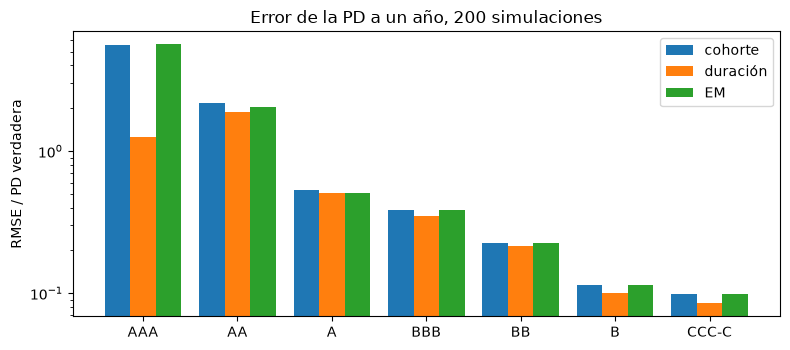

In [10]:
# Dibujar el RMSE relativo de los estimadores de cohorte, duración y EM por grado
fig, ax = plt.subplots(figsize=(8, 3.6))
width = 0.27
for k, (name, color) in enumerate((("cohort", "tab:blue"), ("duration", "tab:orange"), ("em", "tab:green"))):
    rel = np.array(study[name]["rmse"]) / truth
    ax.bar(np.arange(7) + (k - 1) * width, rel, width, color=color, label={"cohort": "cohorte", "duration": "duración", "em": "EM"}[name])
ax.set_yscale("log")
ax.set_xticks(range(7))
ax.set_xticklabels(grades)
ax.set_ylabel("RMSE / PD verdadera")
ax.set_title("Error de la PD a un año, 200 simulaciones")
ax.legend()
fig.tight_layout()
plt.show()

### Paso 8: una segunda agencia

El mismo estimador agrupado corre sobre las cohortes de cualquier agencia. La página de transiciones de Fitch tiene una categoría de incumplimiento; la de Moody's no la tiene, así que no se puede leer una PD de una matriz de Moody's (el artefacto lleva `pd.d4` vacío para ella). La celda siguiente pone lado a lado la PD promedio de largo plazo de S&P y de Fitch, de los artefactos versionados.

In [11]:
# PD promedio de largo plazo (definición d4) de S&P y de Fitch, y las cohortes que aporta cada agencia
lra_sp = np.array(sp["outputs"]["lra"]["d4"]["rate"], dtype=float)
lra_fitch = np.array(fitch["outputs"]["lra"]["d4"]["rate"], dtype=float)
print(f"{'grado':8s}{'S&P':>12s}{'Fitch':>12s}")
for g in range(7):
    print(f"{grades[g]:8s}{lra_sp[g]:12.5f}{lra_fitch[g]:12.5f}")
print("cohortes, S&P y Fitch:", sp["outputs"]["lra"]["d4"]["cohorts"][5], fitch["outputs"]["lra"]["d4"]["cohorts"][5])

grado            S&P       Fitch
AAA          0.00000     0.00000
AA           0.00005     0.00000
A            0.00030     0.00000
BBB          0.00079     0.00027
BB           0.00336     0.00147
B            0.01330     0.00491
CCC-C        0.08608     0.03649
cohortes, S&P y Fitch: 26 24


## Resultados

- **Agrupación.** Las 26 tablas anuales se agrupan en una matriz igual a la versionada (mayor diferencia 0,0). AAA descansa en 1.895 calificaciones agrupadas y ningún incumplimiento, AA en un incumplimiento en 20.192, B en 372 incumplimientos en 31.712.
- **Un grado delgado necesita un intervalo.** El intervalo de Wald de AAA tiene largo cero, mientras que los de Agresti-Coull y Jeffreys conservan cotas superiores de 0,244% y 0,132%. Los tres intervalos del motor igualan a los versionados en los siete grados.
- **Cohorte frente a duración, sobre una verdad conocida.** Desde un conjunto de datos con semilla de 7.113 deudores y 10.953 estadías, el estimador de cohorte lee 0 para AAA (la PD a un año verdadera es 0,0066%) y el de duración 0,0204%. En 200 simulaciones la estimación de cohorte de AAA es exactamente cero en el 99% de ellas (AA: 83%) y la de duración nunca lo es; el error del estimador de duración relativo a la PD es 1,25 para AAA frente a 5,61 del de cohorte. De A a CCC-C los tres estimadores tienen errores relativos parecidos, de cerca de 0,5 en A a cerca de 0,1 en B y CCC-C, así que la elección importa donde los datos son delgados.
- **EM no recupera AAA.** El generador EM de las instantáneas tiene un error relativo de 5,63 para AAA, el del estimador de cohorte, y nunca devuelve cero: es siempre un generador válido, pero ve las mismas instantáneas anuales.
- **Aalen-Johansen** da una matriz para cualquier par de fechas sin supuesto de homogeneidad y cumple exactamente P(0, 2) = P(0, 1) P(1, 2). Sus dos años sueltos difieren porque son dos muestras de una cadena.
- **Conteos reales.** EM sobre las 26 cohortes reales de S&P converge en 116 iteraciones al generador versionado (mayor diferencia 0,0). Las PD promedio de largo plazo de Fitch son menores que las de S&P en todos los grados de AA a CCC-C (B: 0,49% frente a 1,33%; CCC-C: 3,65% frente a 8,61%), sobre 24 cohortes frente a 26.

Lo que este cuaderno no muestra: si el generador existe y qué reparación usar (cuaderno 03), si el supuesto de Markov se cumple (cuaderno 04), ni cómo la definición de incumplimiento y los retiros sesgan una PD (cuaderno 10).

## Resumen

- El estimador de cohorte agrupa instantáneas anuales y no ve nada de lo que ocurre dentro del año; el de duración usa cada salto y el tiempo en cada grado; Aalen-Johansen abandona la homogeneidad en el tiempo; EM encuentra un generador válido solo desde instantáneas.
- En un grado delgado el estimador de cohorte devuelve exactamente cero la mayor parte del tiempo y el intervalo de Wald tiene ancho cero; el estimador de duración y el intervalo de Jeffreys no.
- Los estimadores se comparan sobre datos cuya verdad se conoce, en muchas simulaciones, nunca sobre una sola muestra.
- Cada recálculo se compara con el artefacto versionado tras nombrar la versión del motor que lo calculó.

**Qué probar después.** Cambia la semilla de la simulación del Paso 3 y mira moverse las estimaciones de AAA; luego lee el cuaderno 03 sobre el problema de inmersión.

## Referencias

- ESMA, publicación CEREP de calificaciones y transiciones de agencias calificadoras. https://registers.esma.europa.eu/cerep-publication/
- Anderson, T. W. y Goodman, L. A. (1957), Statistical inference about Markov chains, Annals of Mathematical Statistics 28(1), ecuaciones 2.8 y 2.9. https://doi.org/10.1214/aoms/1177707039
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Schuermann, T. y Hanson, S. (2004), Estimating probabilities of default, FRBNY Staff Report 190. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr190.pdf
- Lando, D. y Skodeberg, T. M. (2002), Analyzing rating transitions and rating drift with continuous observations, Journal of Banking and Finance 26(2-3), doi 10.1016/S0378-4266(01)00228-X.
- Aalen, O. O. y Johansen, S. (1978), An empirical transition matrix for non-homogeneous Markov chains based on censored observations, Scandinavian Journal of Statistics 5(3), 141-150.
- Bladt, M. y Sorensen, M. (2005), Statistical inference for discretely observed Markov jump processes, Journal of the Royal Statistical Society B 67(3), y Smith, A. y dos Reis, G. (2018), Quantitative Finance, doi 10.1080/14697688.2017.1383627.